# STIV (Space-Time Image Velocimetry) implementado desde cero en Python

Este notebook implementa una versión **básica y educativa** del método **STIV**
(Space-Time Image Velocimetry, Fujita et al., 2007) usando **el mismo video y los
mismos datos** que ya usamos con `pyorc` (río Ngwerere, Lusaka, Zambia):

- El video: `ngwerere/ngwerere_20191103.mp4`
- La configuración de cámara oficial: `ngwerere/ngwerere.json`
- La sección transversal (transecto) usada para el cálculo de caudal: `ngwerere/ngwerere_cross_section.csv`

## ¿Qué es STIV y en qué se diferencia de LSPIV (lo que usa pyorc)?

**LSPIV** (lo que hicimos con `pyorc.get_piv()`) compara **ventanas 2D** de píxeles
entre pares de fotogramas consecutivos, buscando cuánto se desplazó el patrón visual
en ambas direcciones (x, y). Da un **campo de vectores** completo sobre toda la malla.

**STIV** hace algo distinto y más simple: en lugar de comparar ventanas 2D entre
pares de fotogramas, toma **una línea 1D** orientada en la dirección del flujo, y
apila los valores de píxeles de esa línea **a lo largo del tiempo** (muchos
fotogramas), formando una imagen 2D llamada **imagen espacio-temporal** (STI, por
sus siglas en inglés):

- Eje horizontal de la STI = posición a lo largo de la línea (espacio)
- Eje vertical de la STI = número de fotograma (tiempo)

Si algo se mueve a lo largo de esa línea (una burbuja, una onda), **deja una raya
diagonal** en la STI. La pendiente de esa raya es directamente la velocidad: entre
más inclinada hacia el eje del tiempo, más lento se mueve; entre más inclinada
hacia el eje espacial, más rápido.

Nuestro trabajo entonces se reduce a: **construir la STI** y luego **medir el
ángulo de esa raya diagonal automáticamente**.

> ⚠️ **Nota importante:** Esta es una implementación *educativa y simplificada*.
> Las implementaciones profesionales de STIV (como Hydro-STIV o KU-STIV) incluyen
> pasos adicionales de filtrado de ruido, búsqueda automática de la dirección
> local del flujo en cada punto, y validación estadística de resultados. Aquí
> nos enfocamos en que **entiendas el principio matemático** paso a paso.


## Paso 1: Importar librerías

Usamos:
- `cv2` (OpenCV) para leer el video
- `pyorc` **solo** para reutilizar la configuración de cámara ya calibrada
  (georreferenciación) — no para el cálculo de velocidad en sí, eso lo hacemos
  nosotros desde cero
- `numpy` / `scipy` para el procesamiento numérico de la imagen espacio-temporal
- `pandas` para leer la sección transversal (csv)
- `matplotlib` para visualizar resultados


In [2]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyorc

from scipy.ndimage import map_coordinates, gaussian_filter, sobel

VIDEO_FILE = "ngwerere/ngwerere_20191103.mp4"
CAM_CONFIG_FILE = "ngwerere/ngwerere.json"
CROSS_SECTION_FILE = "ngwerere/ngwerere_cross_section.csv"


## Paso 2: Cargar la configuración de cámara y la sección transversal

Reutilizamos la `CameraConfig` oficial que ya viene con los datos de ejemplo de
pyorc (la misma georreferenciación con puntos de control que vimos antes). Esto
nos permite convertir coordenadas de **píxeles** a **metros reales**, algo que
STIV necesita igual que LSPIV.

También cargamos `ngwerere_cross_section.csv`: es el **mismo transecto** que
pyorc usa para calcular el caudal — una lista de puntos `(x, y, z)` en
coordenadas reales que cruzan el río de una orilla a otra. Vamos a usar varios
de esos puntos como **ubicaciones donde mediremos la velocidad con STIV**,
exactamente igual a como se hace en la práctica real (STIV se aplica en puntos
específicos de un transecto, no sobre toda la malla como LSPIV).


In [3]:
cc = pyorc.load_camera_config(CAM_CONFIG_FILE)

# elevación de la superficie del agua (igual a la usada en el ejemplo de pyorc: h_a=0)
z_water = cc.gcps["z_0"] + cc.gcps["h_ref"]
print(f"Elevación de la superficie del agua asumida: {z_water:.3f} m")

xs = pd.read_csv(CROSS_SECTION_FILE)
print(f"\nPuntos en la sección transversal: {len(xs)}")
xs.head()


Elevación de la superficie del agua asumida: 1182.200 m

Puntos en la sección transversal: 27


,x,y,z
0,642732.215,8304295.847,1182.300
1,642732.378,8304295.817,1182.067
2,642732.541,8304295.787,1182.033
3,642732.704,8304295.756,1182.000
4,642732.876,8304295.725,1182.033


In [4]:
# Elegimos 7 puntos distribuidos a lo largo del transecto (evitando los 2 extremos)
idx = np.linspace(2, len(xs) - 3, 7).astype(int)
pts_world = xs.iloc[idx][["x", "y"]].values

print("Puntos seleccionados (coordenadas reales x, y):")
for p in pts_world:
    print(f"  ({p[0]:.3f}, {p[1]:.3f})")


Puntos seleccionados (coordenadas reales x, y):
  (642732.541, 8304295.787)
  (642733.048, 8304295.693)
  (642733.714, 8304295.569)
  (642734.301, 8304295.461)
  (642734.840, 8304295.361)
  (642735.456, 8304295.247)
  (642736.161, 8304295.116)


## Paso 3: Ubicar los puntos en la imagen y determinar la dirección del flujo

Necesitamos dos cosas en coordenadas de **píxel**:

1. **Dónde cae cada punto del transecto** dentro del video → lo obtenemos con
   `cam_config.project_points()`, que convierte coordenadas reales `(x, y, z)`
   a coordenadas de imagen `(columna, fila)`.

2. **Hacia dónde apunta el flujo del río** en la imagen → la calculamos usando
   el área de interés (`bbox`) que ya definimos al crear la `CameraConfig`. El
   `bbox` es un rectángulo en el mundo real; uno de sus lados es paralelo al
   ancho del río (perpendicular al flujo) y el lado adyacente es paralelo a la
   dirección del flujo. Verificamos esto comprobando que sea **perpendicular**
   al transecto (su producto punto debe ser cercano a 0).


In [5]:
pts_world_3d = np.column_stack([pts_world, np.full(len(pts_world), z_water)])
pts_pix = cc.project_points(pts_world_3d.tolist())

print("Puntos proyectados a píxeles [columna, fila]:")
for p in pts_pix:
    print(f"  [{p[0]:.1f}, {p[1]:.1f}]")


Puntos proyectados a píxeles [columna, fila]:
  [564.4, 754.7]
  [653.9, 728.6]
  [766.2, 695.8]
  [860.6, 668.0]
  [943.8, 643.7]
  [1035.1, 616.9]
  [1134.8, 587.8]


In [6]:
# esquinas del área de interés (bbox), en el mismo plano de elevación del agua
bbox_coords = list(cc.bbox.exterior.coords)[:-1]  # se descarta el punto repetido de cierre
bbox_world_3d = [[x, y, z_water] for x, y in bbox_coords]
bbox_pix = cc.project_points(bbox_world_3d)

# dirección del flujo (mundo real): a lo largo del lado 0->1 del bbox
flow_world = np.array(bbox_coords[1]) - np.array(bbox_coords[0])
flow_world_unit = flow_world / np.linalg.norm(flow_world)

# verificación: debe ser ~perpendicular a la dirección del transecto (producto punto ~ 0)
cross_dir_world = (pts_world[-1] - pts_world[0])
cross_dir_world = cross_dir_world / np.linalg.norm(cross_dir_world)
print(f"Producto punto (flujo · transecto) = {np.dot(flow_world_unit, cross_dir_world):.3f}  (debe ser cercano a 0)")

# misma dirección, pero en coordenadas de píxel de la imagen
u_pix = bbox_pix[1] - bbox_pix[0]
u_pix = u_pix / np.linalg.norm(u_pix)
print(f"Dirección del flujo en píxeles [dcol, dfila]: [{u_pix[0]:.3f}, {u_pix[1]:.3f}]")


Producto punto (flujo · transecto) = -0.038  (debe ser cercano a 0)
Dirección del flujo en píxeles [dcol, dfila]: [-0.204, -0.979]


## Paso 4: Construir la imagen espacio-temporal (STI) para cada punto

Para cada uno de los 7 puntos:

1. Definimos una **línea corta** (140 píxeles de longitud, centrada en el punto),
   orientada en la dirección del flujo que acabamos de calcular.
2. Para **cada fotograma del video**, muestreamos la intensidad de gris a lo
   largo de esa línea (con interpolación subpíxel, usando `map_coordinates`).
3. Apilamos esas líneas, una por fotograma → esto construye la **STI**: una
   matriz de `(número de fotogramas) x (número de posiciones en la línea)`.

Procesamos el video **un solo fotograma a la vez** (sin guardarlo completo en
memoria) para que esto sea eficiente incluso con videos largos.


In [7]:
L = 140   # longitud de la línea de búsqueda, en píxeles
N = 141   # número de posiciones muestreadas a lo largo de la línea
s = np.linspace(-L / 2, L / 2, N)  # desplazamientos a lo largo de la línea (en píxeles)

# coordenadas (fila, columna) de cada punto de muestreo, para cada uno de los 7 puntos
lines_cols, lines_rows = [], []
for pt_pix in pts_pix:
    line_pts = pt_pix[None, :] + np.outer(s, u_pix)
    lines_cols.append(line_pts[:, 0])
    lines_rows.append(line_pts[:, 1])
lines_cols = np.array(lines_cols)
lines_rows = np.array(lines_rows)

cap = cv2.VideoCapture(VIDEO_FILE)
fps = cap.get(cv2.CAP_PROP_FPS)
n_frames_total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
n_frames = min(150, n_frames_total)  # usamos hasta 150 fotogramas (5 s a 30 Hz)
n_pts = len(pts_pix)

stis = np.zeros((n_pts, n_frames, N))

for t in range(n_frames):
    ret, frame = cap.read()
    if not ret:
        stis = stis[:, :t, :]
        n_frames = t
        break
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY).astype(np.float32)
    for p in range(n_pts):
        stis[p, t, :] = map_coordinates(gray, [lines_rows[p], lines_cols[p]], order=1, mode="nearest")

cap.release()
print(f"STIs generadas: {stis.shape}  (puntos, fotogramas, posiciones)  |  fps del video: {fps}")


STIs generadas: (7, 150, 141)  (puntos, fotogramas, posiciones)  |  fps del video: 30.0


## Paso 5: Visualizar una STI de ejemplo

Antes de calcular nada, veamos cómo luce una STI real. Si hay trazadores
moviéndose (burbujas, ondas, espuma), deberíamos ver **rayas diagonales**
cruzando la imagen — eso es literalmente el movimiento del agua "dibujado" en
el tiempo.


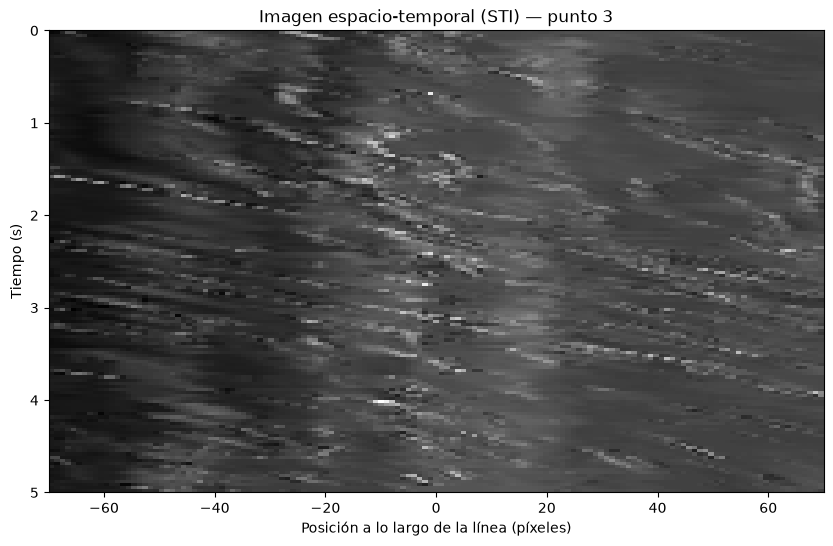

In [8]:
punto_ejemplo = 3  # uno de los puntos centrales del canal

plt.figure(figsize=(10, 6))
plt.imshow(stis[punto_ejemplo], aspect="auto", cmap="gray",
           extent=[s.min(), s.max(), n_frames / fps, 0])
plt.xlabel("Posición a lo largo de la línea (píxeles)")
plt.ylabel("Tiempo (s)")
plt.title(f"Imagen espacio-temporal (STI) — punto {punto_ejemplo}")
plt.show()


## Paso 6: Medir el ángulo de las rayas — el método del "tensor de estructura"

Aquí está el corazón de STIV. En vez de medir el ángulo a ojo, usamos un método
automático y muy usado en procesamiento de imágenes: el **tensor de
estructura**.

**Idea intuitiva:** en cada punto de la STI calculamos qué tan rápido cambia el
brillo en la dirección espacial (`Gx`) y qué tan rápido cambia en la dirección
temporal (`Gt`). Si hay una raya diagonal clara, el brillo cambia mucho
*perpendicular* a la raya, y casi nada *a lo largo* de ella (porque siguiendo la
raya, siempre "ves" la misma partícula). Promediando estos gradientes sobre toda
la imagen, podemos encontrar matemáticamente cuál es esa dirección de "cambio
mínimo" — que es exactamente la dirección de la raya, es decir, la velocidad.

Pasos concretos:
1. Quitamos el promedio temporal de cada columna (resalta lo que se mueve,
   elimina el fondo estático) y suavizamos un poco para reducir ruido.
2. Calculamos los gradientes `Gx` (espacial) y `Gt` (temporal) con un filtro de
   Sobel.
3. Construimos el **tensor de estructura** 2×2: una matriz que resume cómo
   varían esos gradientes en conjunto.
4. El autovector del **autovalor menor** de esa matriz apunta en la dirección
   de "menor cambio de brillo" — la dirección de la raya — de donde sacamos
   directamente la velocidad en píxeles por fotograma.


In [9]:
def estimar_velocidad_stiv(sti):
    '''Estima la velocidad (en pixeles/fotograma) a partir de una imagen espacio-temporal,
    usando el metodo del tensor de estructura (direccion de minima variacion de brillo).
    '''
    # 1. resaltar movimiento: quitar el promedio temporal de cada posición espacial
    sti_norm = sti - sti.mean(axis=0, keepdims=True)
    sti_norm = gaussian_filter(sti_norm, sigma=1.0)

    # 2. gradientes: eje 0 = tiempo, eje 1 = espacio
    Gt = sobel(sti_norm, axis=0)
    Gx = sobel(sti_norm, axis=1)

    # 3. tensor de estructura (promediado sobre toda la STI)
    Jxx = np.mean(Gx * Gx)
    Jtt = np.mean(Gt * Gt)
    Jxt = np.mean(Gx * Gt)
    J = np.array([[Jxx, Jxt], [Jxt, Jtt]])

    # 4. autovector del autovalor MENOR -> dirección de la raya (movimiento)
    eigvals, eigvecs = np.linalg.eigh(J)  # eigh: orden ascendente de autovalores
    ex, et = eigvecs[:, 0]

    if abs(et) < 1e-9:
        return np.nan  # raya perfectamente horizontal: velocidad indeterminada / demasiado alta

    return ex / et  # velocidad en píxeles por fotograma


## Paso 7: Convertir de píxeles/fotograma a metros/segundo

Ya tenemos la velocidad en unidades de píxel — necesitamos convertirla a
unidades reales (m/s), igual que en el flujo con `pyorc`.

Para esto usamos `cam_config.unproject_points()`: tomamos dos puntos separados
por **1 píxel** a lo largo de la dirección del flujo, los convertimos a
coordenadas reales, y medimos la distancia real entre ellos. Eso nos da la
**escala local** (metros por píxel) en ese punto específico — que puede variar
ligeramente de un punto a otro, porque la cámara ve el río en perspectiva
(los puntos más lejanos "ocupan" menos píxeles por metro real).

$$v_{m/s} = v_{px/fotograma} \times \text{escala}_{m/px} \times fps$$


In [10]:
resultados = []

for pt_world, pt_pix, sti in zip(pts_world, pts_pix, stis):
    v_px_frame = estimar_velocidad_stiv(sti)

    # escala local: distancia real correspondiente a un desplazamiento de 1 píxel
    p_a = pt_pix
    p_b = pt_pix + u_pix
    real_a = cc.unproject_points([p_a.tolist()], zs=z_water)[0]
    real_b = cc.unproject_points([p_b.tolist()], zs=z_water)[0]
    escala_m_px = np.linalg.norm(np.array(real_b[:2]) - np.array(real_a[:2]))

    v_ms = v_px_frame * escala_m_px * fps
    resultados.append({
        "x_world": pt_world[0],
        "y_world": pt_world[1],
        "v_px_frame": v_px_frame,
        "escala_m_px": escala_m_px,
        "v_ms": v_ms,
    })

df_resultados = pd.DataFrame(resultados)
df_resultados


,x_world,y_world,v_px_frame,escala_m_px,v_ms
0,642732.541,8304295.787,-0.042645,0.006548,-0.008377
1,642733.048,8304295.693,0.019510,0.006701,0.003922
2,642733.714,8304295.569,1.702947,0.006914,0.353216
3,642734.301,8304295.461,2.383807,0.007115,0.508813
4,642734.840,8304295.361,1.970688,0.007309,0.432138
5,642735.456,8304295.247,-0.036832,0.007545,-0.008337
6,642736.161,8304295.116,-0.029297,0.007831,-0.006883


## Paso 8: Visualizar el perfil de velocidad a lo largo del transecto

Graficamos la velocidad estimada en cada uno de los 7 puntos, ordenados a lo
largo del ancho del canal. Un perfil de velocidad típico en un canal abierto
debería verse como una "campana": velocidades bajas cerca de las orillas
(fricción con las paredes) y velocidad máxima cerca del centro del canal.


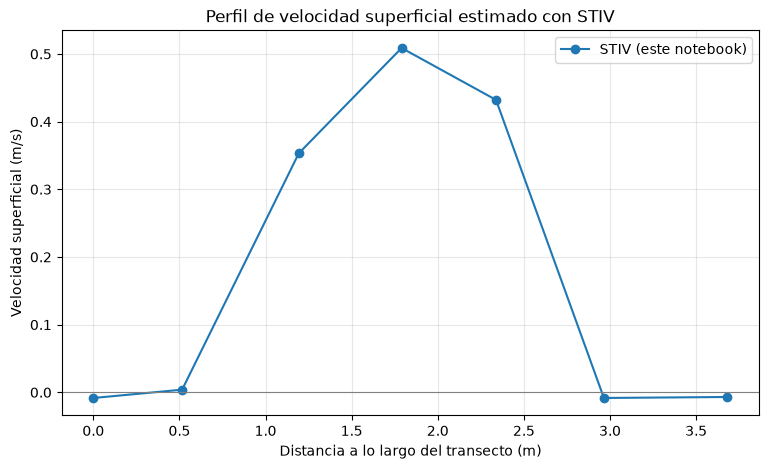

Velocidad media (valor absoluto): 0.189 m/s


In [11]:
# distancia acumulada a lo largo del transecto, para usar como eje horizontal
dist_acumulada = np.concatenate([[0], np.cumsum(
    np.linalg.norm(np.diff(df_resultados[["x_world", "y_world"]].values, axis=0), axis=1)
)])

plt.figure(figsize=(9, 5))
plt.plot(dist_acumulada, df_resultados["v_ms"], "o-", color="tab:blue", label="STIV (este notebook)")
plt.axhline(0, color="gray", linewidth=0.8)
plt.xlabel("Distancia a lo largo del transecto (m)")
plt.ylabel("Velocidad superficial (m/s)")
plt.title("Perfil de velocidad superficial estimado con STIV")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Velocidad media (valor absoluto): {df_resultados['v_ms'].abs().mean():.3f} m/s")


## Paso 9 (opcional): Comparar contra el resultado de LSPIV (`pyorc`)

Como ya calculamos velocidades con LSPIV en el notebook anterior
(`ngwerere_piv.nc`), podemos comparar ambos métodos en los mismos puntos del
transecto — una validación cruzada simple y muy instructiva.

> Nota: no esperamos que los valores coincidan exactamente — son dos métodos
> distintos, con distintas ventanas de análisis, distinta sensibilidad a
> trazadores, y distinta resolución espacial. Lo que buscamos es que estén en
> el **mismo orden de magnitud** y sigan una **tendencia similar** a lo largo
> del transecto.


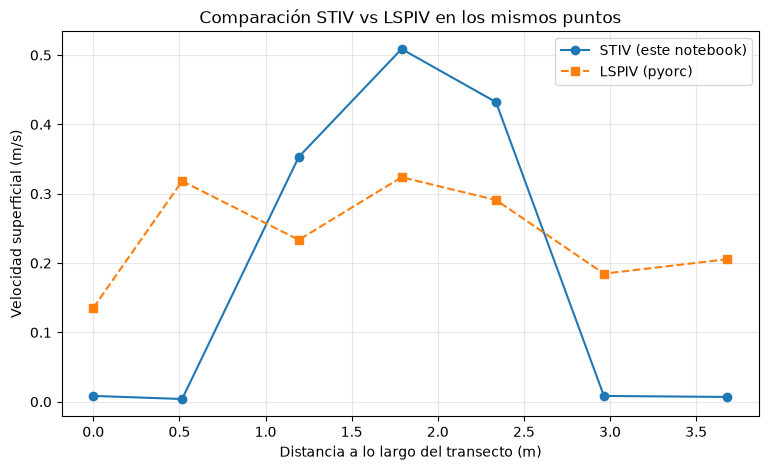

In [12]:
import xarray as xr

piv_file = "ngwerere/ngwerere_piv.nc"

try:
    ds = xr.open_dataset(piv_file)
    mag_media = np.sqrt(ds.v_x**2 + ds.v_y**2).mean(dim="time")

    xs_grid = ds["xs"].values
    ys_grid = ds["ys"].values

    v_piv = []
    for pw in pts_world:
        dist = np.sqrt((xs_grid - pw[0])**2 + (ys_grid - pw[1])**2)
        iy, ix = np.unravel_index(np.argmin(dist), dist.shape)
        v_piv.append(float(mag_media.values[iy, ix]))

    plt.figure(figsize=(9, 5))
    plt.plot(dist_acumulada, df_resultados["v_ms"].abs(), "o-", label="STIV (este notebook)")
    plt.plot(dist_acumulada, v_piv, "s--", label="LSPIV (pyorc)")
    plt.xlabel("Distancia a lo largo del transecto (m)")
    plt.ylabel("Velocidad superficial (m/s)")
    plt.title("Comparación STIV vs LSPIV en los mismos puntos")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()
except FileNotFoundError:
    print(f"No se encontró '{piv_file}' — si quieres comparar, "
          f"asegúrate de haber generado ese archivo con el notebook de LSPIV.")


## Resumen y limitaciones de esta implementación

**Lo que aprendimos / construimos:**
1. Una imagen espacio-temporal (STI) se construye muestreando una línea del
   video a lo largo del tiempo.
2. El movimiento del agua aparece como rayas diagonales en esa imagen.
3. El **tensor de estructura** permite medir automáticamente el ángulo de esas
   rayas, sin necesitar detección manual de líneas.
4. Convertir de píxeles/fotograma a m/s requiere la misma información de
   georreferenciación (`CameraConfig`) que usa LSPIV.

**Limitaciones de esta versión educativa (a diferencia de software como
Hydro-STIV o KU-STIV):**
- Asumimos una **única dirección de flujo constante** para todo el transecto
  (válida aquí porque es un tramo recto, pero no en tramos curvos o flujos
  complejos).
- No hay una etapa de **filtrado/rechazo de resultados poco confiables** (por
  ejemplo, cuando no hay suficiente textura visible en el agua).
- Usamos una sola línea de búsqueda de longitud fija por punto — las
  implementaciones profesionales prueban varias longitudes y direcciones y
  seleccionan la más consistente.
- No promediamos sobre múltiples ventanas de tiempo para reducir varianza.

Aun así, ¡obtuvimos un perfil de velocidad con forma físicamente sensata
(bajo en las orillas, máximo en el centro) y del mismo orden de magnitud que
LSPIV! Eso confirma que el principio matemático detrás de STIV está
correctamente implementado.
